<a href="https://colab.research.google.com/github/Harsha2oo5/project-demo/blob/main/FASDD_CLIP_Hard_Negatives.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FASDD-CV hard-negative discovery with CLIP

**Honeywell × BMSCE vision-based flame detection — dataset audit, not model training.**

This notebook searches FASDD-CV images that carry **no fire and no smoke annotations** for nine visually
confusing non-fire conditions that could cause flame false alarms:

| # | Category | # | Category | # | Category |
|---|---|---|---|---|---|
| 1 | Welding | 4 | Reflections on metal/glass | 7 | Red/orange clothing |
| 2 | Grinding sparks | 5 | Vehicle headlights/tail lights | 8 | Heaters / glowing elements |
| 3 | Sunlight through windows | 6 | LED indicator lights | 9 | Screens displaying fire |

**Method.** Pretrained OpenAI CLIP ViT-B/32 (frozen, never fine-tuned) embeds each image and several detailed text
descriptions per category. Images are ranked per category by cosine similarity, the top 50 are shown on contact
sheets, and a person verifies each candidate as **Confirmed / Possible / Incorrect**.

**Read before interpreting results**
- CLIP cosine similarities are **retrieval scores, not probabilities**. They are typically 0.15–0.35 and are not
  comparable across categories or prompts.
- An image without annotations is **not a verified negative**. The reviewer can flag any candidate that visibly
  contains a real flame; those go to a separate label-review list.
- Only human-verified results count as evidence. A category with no confirmed hits in a sample is
  *not established*, not *absent*.
- The original images, annotations and splits are only read, never modified.

**How to run (Colab, T4 GPU):** `Runtime → Change runtime type → T4 GPU`, make sure the dataset is at
`/content/custom_data/`, review the configuration cell, then `Runtime → Run all`. Review candidates in the
verification interface in section 9. Re-running is safe: embeddings are cached and earlier reviews are kept.

## 1. Setup

In [3]:
import os
import sys
import subprocess
import importlib.util

CLIP_COMMIT = "dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1"
CLIP_DIR = "/content/CLIP"

# Install only the small dependencies
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "ftfy", "regex"],
    check=True
)

# Download the official OpenAI CLIP repository
if not os.path.exists(CLIP_DIR):
    subprocess.run(
        ["git", "clone", "https://github.com/openai/CLIP.git", CLIP_DIR],
        check=True
    )

# Checkout the exact version required by the notebook
subprocess.run(
    ["git", "-C", CLIP_DIR, "checkout", CLIP_COMMIT],
    check=True
)

# Import CLIP directly, without building a package
sys.path.insert(0, CLIP_DIR)

import clip

print("CLIP imported successfully!")
print("CLIP location:", clip.__file__)

CLIP imported successfully!
CLIP location: /content/CLIP/clip/__init__.py


## 2. Configuration

Everything that changes between runs is here. To scale from the pilot to every candidate image set
`sample_size=None`. That creates a separate run folder, reuses cached pilot embeddings, and imports reviews
already made for the same image and category.

In [11]:
CONFIG = dict(
    data_root="/content/custom_data",
    splits=["train", "val", "test"],
    candidate_pool="no_annotations",  # "no_annotations": no fire AND no smoke boxes (expected 39,199 images)
                                      # "no_fire": also includes smoke-only images (negatives for flame detection)
    sample_size=500,                  # pilot size; None = every candidate image
    seed=42,
    model_name="ViT-B/32",
    batch_size=128,                   # 128 fits comfortably on a T4 in fp16
    num_workers=2,
    aggregation="mean",               # "mean" or "max" over each category's positive prompts
    subtract_contrastive=False,       # True: rank by (aggregated score - best contrastive-prompt score)
    top_k=50,                         # candidates per category on contact sheets / for review
    prompt_top_k=50,                  # rows kept per individual prompt in prompt_rankings.csv
    save_to_drive=False,               # in Colab, keep outputs on Google Drive so they survive disconnects
    drive_dir="/content/drive/MyDrive/HoneywellTraining/experiments/clip_hard_negatives",
    local_dir="/content/clip_hard_negatives",
    run_name=None,                    # None = derived from pool, sample size and seed
    import_previous_reviews=True,     # reuse verdicts from other runs for the same (category, image)
    show_contact_sheets=True,
    reviewer="",                      # your name or initials, stored with each verdict
)

# Published Kaggle statistics, used only to warn about a different dataset copy.
EXPECTED_COUNTS = {"train": (63546, 87682), "val": (15884, 21453), "test": (15884, 17242)}
EXPECTED_NO_ANNOTATION_TOTAL = 39199
EXPECTED_CATEGORY_IDS = {0: "fire", 1: "smoke"}

In [12]:
import datetime as dt
import hashlib
import io
import json
import math
import os
import platform
import shutil
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import torch
import torchvision
from IPython.display import Markdown, display
from PIL import Image, ImageDraw, ImageFont, ImageOps
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

import clip

assert CONFIG["aggregation"] in ("mean", "max"), "aggregation must be 'mean' or 'max'"
assert CONFIG["candidate_pool"] in ("no_annotations", "no_fire")

IN_COLAB = "google.colab" in sys.modules
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else None
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

if IN_COLAB and CONFIG["save_to_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path(CONFIG["drive_dir"])
else:
    OUTPUT_ROOT = Path(CONFIG["local_dir"])

K = CONFIG["top_k"]
RUN_NAME = CONFIG["run_name"] or f'{CONFIG["candidate_pool"]}_n{CONFIG["sample_size"] or "all"}_seed{CONFIG["seed"]}'
RUN_DIR = OUTPUT_ROOT / "runs" / RUN_NAME
CACHE_DIR = OUTPUT_ROOT / "cache"
TOPK_DIR = RUN_DIR / f"top{K}"
SHEET_DIR = RUN_DIR / "contact_sheets"
VERIFY_DIR = RUN_DIR / "verification"
for d in (RUN_DIR, CACHE_DIR, TOPK_DIR, SHEET_DIR, VERIFY_DIR):
    d.mkdir(parents=True, exist_ok=True)


def utc_now():
    return dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def atomic_csv(df, path, **kwargs):
    # Write to a temporary file first so a disconnect never leaves a half-written CSV.
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, index=False, **kwargs)
    os.replace(tmp, path)


def atomic_json(value, path):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, default=str), encoding="utf-8")
    os.replace(tmp, path)


ENVIRONMENT = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
                   pillow=PIL.__version__, numpy=np.__version__, pandas=pd.__version__,
                   clip_commit=CLIP_COMMIT, device=DEVICE, gpu=GPU_NAME, in_colab=IN_COLAB)
print(json.dumps(ENVIRONMENT, indent=2))
print("Run folder:", RUN_DIR)
if DEVICE == "cpu":
    print("WARNING: no GPU found - this works, but embedding will be slow. In Colab choose a T4 runtime.")

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "pillow": "11.3.0",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "clip_commit": "dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1",
  "device": "cuda",
  "gpu": "Tesla T4",
  "in_colab": true
}
Run folder: /content/clip_hard_negatives/runs/no_annotations_n500_seed42


## 3. Dataset loading and validation

Checks the folder layout, parses each split's COCO file, compares counts with the published statistics, and
finds the candidate images. Fire and smoke categories are matched **by name**, not by assumed IDs. Missing
candidate files are listed and excluded. Unreadable files are detected while embedding in section 6.

In [14]:
import os

DATA_ROOT = "/content/custom_data"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

    if len(files) > 5:
        print("  " * (level + 1) + f"... and {len(files)-5} more files")

In [16]:
import os

print("Current working directory:", os.getcwd())
print("Does /content exist?", os.path.exists("/content"))
print("Does dataset folder exist?", os.path.exists("/content/custom_data"))

print("\nFolders inside /content:")
print(os.listdir("/content"))

Current working directory: /content
Does /content exist? True
Does dataset folder exist? False

Folders inside /content:
['.config', 'CLIP', 'clip_hard_negatives', 'sample_data']


In [17]:
!pip install -q kaggle

In [18]:
from google.colab import files
files.upload()


Saving kaggle (2).json to kaggle (2).json


{'kaggle (2).json': b'{"username":"ksaisriharsha2oo5","key":"53529f9fa9826f147420e864a59e9ac6"}'}

In [21]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle (2).json", "/root/.kaggle/kaggle (2).json")
os.chmod("/root/.kaggle/kaggle (2).json", 0o600)

!kaggle datasets download -d yuulind/fasdd-cv-coco -p /content

Dataset URL: https://www.kaggle.com/datasets/yuulind/fasdd-cv-coco
License(s): other
100% 11.4G/11.4G [11:10<00:00, 18.3MB/s]



In [23]:
import zipfile
import os

zip_path = "/content/fasdd-cv-coco.zip"
extract_path = "/content/custom_data"

os.makedirs(extract_path, exist_ok=True)

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Dataset folders:", os.listdir(extract_path))

Extracting dataset...
Extraction completed!
Dataset folders: ['images', 'annotations']


In [24]:
DATA_ROOT = Path(CONFIG["data_root"])
problems = [f"missing: {p}" for p in
            [DATA_ROOT / "images" / s for s in CONFIG["splits"]] +
            [DATA_ROOT / "annotations" / f"{s}.json" for s in CONFIG["splits"]] if not p.exists()]
if problems:
    raise FileNotFoundError("Dataset layout is not as expected:\n" + "\n".join(problems))

CANONICAL_NAMES = {"fire": "fire", "flame": "fire", "smoke": "smoke"}


def load_split(split):
    with open(DATA_ROOT / "annotations" / f"{split}.json", encoding="utf-8") as f:
        coco = json.load(f)
    categories = {int(c["id"]): CANONICAL_NAMES.get(str(c["name"]).strip().lower(), str(c["name"]).strip().lower())
                  for c in coco.get("categories", [])}
    if "fire" not in categories.values() or "smoke" not in categories.values():
        raise ValueError(f"{split}: expected fire and smoke categories, found {categories}")
    images, annotations = coco.get("images", []), coco.get("annotations", [])
    ids = [img["id"] for img in images]
    if len(ids) != len(set(ids)):
        raise ValueError(f"{split}: duplicate image ids in {split}.json")
    counts = {i: Counter() for i in ids}
    orphans = 0
    for a in annotations:
        c = counts.get(a["image_id"])
        if c is None:
            orphans += 1
        else:
            c[categories.get(a["category_id"], "unknown")] += 1
    rows = []
    for img in images:
        c = counts[img["id"]]
        rows.append(dict(uid=f'{split}/{img["file_name"]}', split=split, image_id=img["id"],
                         file_name=img["file_name"], width=img.get("width"), height=img.get("height"),
                         n_fire=c["fire"], n_smoke=c["smoke"], n_other=sum(c.values()) - c["fire"] - c["smoke"],
                         image_path=str(DATA_ROOT / "images" / split / img["file_name"])))
    stats = dict(images=len(images), annotations=len(annotations), orphan_annotations=orphans, categories=categories)
    return pd.DataFrame(rows), stats


frames, SPLIT_STATS = [], {}
for split in CONFIG["splits"]:
    df, SPLIT_STATS[split] = load_split(split)
    frames.append(df)
INDEX = pd.concat(frames, ignore_index=True)
assert INDEX["uid"].is_unique, "split/file_name pairs must be unique"

warnings = []
for split, s in SPLIT_STATS.items():
    exp = EXPECTED_COUNTS.get(split)
    if exp and (s["images"], s["annotations"]) != exp:
        warnings.append(f"{split}: {s['images']} images / {s['annotations']} annotations; expected {exp[0]} / {exp[1]}")
    if s["orphan_annotations"]:
        warnings.append(f"{split}: {s['orphan_annotations']} annotations reference unknown image ids")
    if s["categories"] != EXPECTED_CATEGORY_IDS:
        warnings.append(f"{split}: category ids {s['categories']} differ from {EXPECTED_CATEGORY_IDS} (matched by name)")

has_fire, has_smoke = INDEX["n_fire"] > 0, INDEX["n_smoke"] > 0
INDEX["annotation_group"] = np.select(
    [has_fire & has_smoke, has_fire, has_smoke, INDEX["n_other"] > 0],
    ["fire+smoke", "fire only", "smoke only", "other only"], default="no annotations")
group_table = pd.crosstab(INDEX["annotation_group"], INDEX["split"], margins=True, margins_name="total")
no_annotation_total = int((INDEX["annotation_group"] == "no annotations").sum())
if no_annotation_total != EXPECTED_NO_ANNOTATION_TOTAL:
    warnings.append(f"{no_annotation_total} images without annotations; expected {EXPECTED_NO_ANNOTATION_TOTAL}")

split_table = pd.DataFrame([dict(split=s, images=v["images"], annotations=v["annotations"],
                                 expected_images=EXPECTED_COUNTS.get(s, (None, None))[0],
                                 expected_annotations=EXPECTED_COUNTS.get(s, (None, None))[1])
                            for s, v in SPLIT_STATS.items()])
display(split_table)
display(group_table)
for w in warnings:
    print("WARNING:", w)
if not warnings:
    print("Dataset counts match the published statistics.")

if CONFIG["candidate_pool"] == "no_annotations":
    POOL = INDEX[INDEX["annotation_group"] == "no annotations"].copy()
else:
    POOL = INDEX[INDEX["n_fire"] == 0].copy()
POOL["file_exists"] = [os.path.isfile(p) for p in tqdm(POOL["image_path"], desc="checking candidate files")]
MISSING = POOL[~POOL["file_exists"]]
POOL = POOL[POOL["file_exists"]].drop(columns="file_exists").reset_index(drop=True)
print(f"Candidate pool ({CONFIG['candidate_pool']}): {len(POOL):,} readable paths, {len(MISSING):,} missing files")

INDEX.to_csv(RUN_DIR / "images_index.csv.gz", index=False)
atomic_csv(MISSING, RUN_DIR / "missing_images.csv")
DATASET_VALIDATION = dict(split_stats=SPLIT_STATS, annotation_groups=json.loads(group_table.to_json()),
                          no_annotation_total=no_annotation_total, candidate_pool=CONFIG["candidate_pool"],
                          candidate_count=len(POOL), missing_candidate_files=len(MISSING), warnings=warnings)
atomic_json(DATASET_VALIDATION, RUN_DIR / "dataset_validation.json")

,split,images,annotations,expected_images,expected_annotations
0,train,63546,87682,63546,87682
1,val,15884,21453,15884,21453
2,test,15884,17242,15884,17242


split,test,train,val,total
annotation_group,,,,
fire only,2091,8368,2091,12550
fire+smoke,3358,13435,3358,20151
no annotations,6533,26133,6533,39199
smoke only,3902,15610,3902,23414
total,15884,63546,15884,95314


Dataset counts match the published statistics.


checking candidate files:   0%|          | 0/39199 [00:00<?, ?it/s]

Candidate pool (no_annotations): 39,199 readable paths, 0 missing files


## 4. Reproducible, split-proportional sampling

The sample is allocated to train/val/test in proportion to each split's share of the candidate pool (largest-remainder
rounding), so no split dominates. Within a split, images come from a fixed seeded permutation of the sorted file
list, so a larger sample starts with the same images as a smaller one.

In [25]:
def proportional_allocation(counts, n):
    total = sum(counts.values())
    raw = {s: n * c / total for s, c in counts.items()}
    alloc = {s: int(math.floor(v)) for s, v in raw.items()}
    for s in sorted(raw, key=lambda s: (raw[s] - alloc[s], s), reverse=True)[: n - sum(alloc.values())]:
        alloc[s] += 1
    return alloc


pool_counts = {s: int((POOL["split"] == s).sum()) for s in CONFIG["splits"]}
n_sample = len(POOL) if CONFIG["sample_size"] is None else min(int(CONFIG["sample_size"]), len(POOL))
allocation = proportional_allocation(pool_counts, n_sample)

parts = []
for i, split in enumerate(CONFIG["splits"]):
    pool_split = POOL[POOL["split"] == split].sort_values("file_name").reset_index(drop=True)
    order = np.random.default_rng([CONFIG["seed"], i]).permutation(len(pool_split))
    parts.append(pool_split.iloc[order[: allocation[split]]])
SAMPLE = pd.concat(parts, ignore_index=True)
SAMPLE.insert(0, "sample_order", np.arange(len(SAMPLE)))
SAMPLE_HASH = hashlib.sha256("\n".join(SAMPLE["uid"]).encode()).hexdigest()

display(pd.DataFrame({"candidates": pool_counts, "sampled": allocation}).assign(
    share_of_pool=lambda d: (d.candidates / d.candidates.sum()).round(4),
    share_of_sample=lambda d: (d.sampled / max(d.sampled.sum(), 1)).round(4)))
print(f"Sample: {len(SAMPLE):,} images | seed {CONFIG['seed']} | sha256 {SAMPLE_HASH[:16]}...")
atomic_csv(SAMPLE, RUN_DIR / "sample_manifest.csv")

,candidates,sampled,share_of_pool,share_of_sample
train,26133,334,0.6667,0.668
val,6533,83,0.1667,0.166
test,6533,83,0.1667,0.166


Sample: 500 images | seed 42 | sha256 429876c43d724ea6...


## 5. Prompts

Each category has **10–12 positive prompts** that describe distinctive visual evidence such as arc colour, spark
trails, coil glow or a screen bezel. It also has **contrastive prompts** for look-alike scenes. Positive prompts are
ensembled into one category score (mean or max). Contrastive prompts are kept as separate evidence: they can be
subtracted (`subtract_contrastive=True`), and the comparison in section 7 shows how often they win.

CLIP handles negation poorly. A phrase like "…without fire" still contains the word *fire* and can match fire-like
images, so most contrastive prompts describe the alternative scene positively. A separate **fire probe** prompt
set is not a category. It surfaces candidates that may contain a real, unannotated flame.

In [26]:
CATEGORIES = {
    "welding": dict(name="Welding", positive=[
        "a photo of a bright blue-white electric arc between a welding electrode and metal",
        "a welder in a dark welding helmet with an intense arc flash at the weld joint",
        "close-up of a welding torch producing a blinding white arc and glowing molten metal",
        "molten metal glowing orange at an active weld seam on a steel plate",
        "arc welding in a dark workshop with a tiny extremely bright point of light",
        "a MIG welding gun on steel with bright arc light and small spatter sparks",
        "TIG welding with a glowing tungsten electrode and a blue-violet arc",
        "a steel fabrication worker welding a pipe with bright glare from the arc",
        "a construction worker welding steel beams with a bright white arc light",
        "an industrial welding robot arm producing bright arc flashes on a production line",
        "welding fumes lit up by a bright arc flash in a factory at night",
    ], contrastive=[
        "a construction worker holding a power drill, with no welding arc",
        "a worker wearing a welding helmet in a workshop with no arc light",
        "sparks flying from an angle grinder cutting metal",
        "a large open fire with tall orange flames and smoke",
    ]),
    "grinding_sparks": dict(name="Grinding sparks", positive=[
        "a shower of orange sparks scattering from an angle grinder cutting steel",
        "bright metal sparks flying off a spinning grinding wheel",
        "a stream of glowing yellow sparks during metal grinding in a workshop",
        "a worker cutting a steel pipe with a cut-off saw throwing a fan of sparks",
        "long streaks of hot sparks spraying across a dark workshop floor",
        "a bench grinder sharpening a metal tool with sparks shooting out",
        "close-up of a cutting disc on metal with a spray of orange spark trails",
        "sparks bouncing off the floor while a man grinds a steel beam",
        "long-exposure photo of sparks from metal cutting forming bright light trails",
        "a worker in protective gear grinding a weld with a cascade of sparks",
    ], contrastive=[
        "a welder producing a blue-white electric arc with no spray of sparks",
        "fireworks exploding in the night sky",
        "a sparkler burning in someone's hand",
        "a large open fire with tall orange flames and smoke",
    ]),
    "sunlight_windows": dict(name="Sunlight through windows", positive=[
        "bright sunlight streaming through a window into a dark room",
        "golden sunset light shining through window glass onto the floor",
        "orange evening sunlight casting bright window-shaped patches on a wall",
        "sun rays coming through window blinds creating bright stripes of light",
        "strong backlight from a sunny window leaving the room interior dark",
        "warm low sun glaring through a dusty factory window",
        "sunlight through tinted window glass glowing orange",
        "a bright overexposed window in an indoor scene at sunset",
        "beams of sunlight entering a warehouse through skylights",
        "sun shining through thin curtains with a warm orange glow",
    ], contrastive=[
        "a building with flames coming out of a window",
        "a dim indoor room lit by ceiling lamps at night",
        "an outdoor street scene in daylight",
        "sunlight reflecting off a glass building facade",
    ]),
    "reflections_metal_glass": dict(name="Reflections on metal/glass", positive=[
        "a bright sun reflection glinting off a polished metal surface",
        "orange sunset reflected in the glass windows of an office building",
        "specular glare on a shiny stainless steel tank",
        "light reflections on a wet road at night",
        "a car body reflecting bright sunlight",
        "the reflection of a bright lamp in a glossy floor",
        "sunlight reflected off water creating sparkling highlights",
        "glare from a reflective glass facade",
        "orange light reflected on polished metal pipes in a factory",
        "a mirror reflecting a bright light source",
    ], contrastive=[
        "sunlight reflections on glass, without any fire",
        "a burning building with flames reflected in its windows",
        "sunlight shining directly through a window into a room",
        "a dull concrete wall in shade",
    ]),
    "vehicle_lights": dict(name="Vehicle headlights and tail lights", positive=[
        "bright vehicle headlights shining toward the camera at night",
        "red tail lights of cars in traffic at night",
        "a car with its headlights on in the dark",
        "long-exposure light trails from car headlights and tail lights on a highway",
        "glowing red brake lights of a truck on a dark road",
        "an amber turn signal light flashing on a car",
        "headlight glare from oncoming traffic on a wet road at night",
        "an emergency vehicle with flashing red and orange lights at night",
        "close-up of a car rear lamp glowing red",
        "a motorcycle headlight beam in the dark",
    ], contrastive=[
        "bright vehicle headlights without fire",
        "a parked car in daylight with its lights off",
        "a car engulfed in flames",
        "street lamps illuminating an empty road at night",
    ]),
    "led_indicators": dict(name="LED indicator lights", positive=[
        "small red LED indicator lights glowing on an electronic panel",
        "a control panel with green, red and orange status LEDs",
        "blinking LED lights on a network server rack in a dark room",
        "close-up of a glowing orange LED on a circuit board",
        "a power indicator light glowing red on a device in the dark",
        "rows of small bright LED dots on industrial equipment",
        "LED status lamps on a machine control cabinet",
        "a small glowing amber warning light on a car dashboard",
        "red LED digital display numbers glowing in the dark",
        "a string of small orange LED fairy lights",
    ], contrastive=[
        "an electrical panel on fire with flames",
        "an electronic device with all its lights switched off",
        "a large bright floodlight illuminating an area",
        "a burning candle flame in the dark",
    ]),
    "red_orange_clothing": dict(name="Red/orange clothing", positive=[
        "a person wearing a bright orange high-visibility safety vest",
        "a worker in red coveralls in a factory",
        "a woman wearing a bright red dress",
        "a person in an orange jacket walking down a street",
        "construction workers in orange hi-vis jackets and hard hats",
        "a child wearing a red hooded sweatshirt",
        "a person wearing a plain red t-shirt",
        "people in red and orange sports jerseys",
        "close-up of folds of bright orange fabric",
        "a man wearing an orange safety jumpsuit",
        "a red scarf blowing in the wind",
    ], contrastive=[
        "a worker wearing orange safety clothing, without flames",
        "a person standing next to a burning fire",
        "a person wearing dark blue clothing",
        "orange autumn leaves on a tree",
    ]),
    "heaters": dict(name="Heaters and glowing heating elements", positive=[
        "glowing orange coils of an electric space heater",
        "a red-hot heating element inside a toaster",
        "an infrared heater with glowing red bars in a dark room",
        "an electric stove burner glowing red hot",
        "a halogen heater with bright orange glowing tubes",
        "a red-hot glowing steel billet coming out of an industrial furnace",
        "a radiant ceramic heater glowing orange",
        "an electric fireplace with artificial LED flames",
        "close-up of a glowing nichrome wire heating element",
        "an oven heating element glowing bright orange",
    ], contrastive=[
        "a wood fire burning in a fireplace with open flames",
        "a gas stove burner with blue flames",
        "an electric heater that is switched off",
        "a red painted object in a room",
    ]),
    "screens_fire": dict(name="Screens displaying fire", positive=[
        "a television screen showing a video of a burning fire",
        "a computer monitor displaying an image of flames",
        "a smartphone screen showing a fire video",
        "a TV displaying a virtual fireplace video in a living room",
        "a projector screen showing an image of flames",
        "a news broadcast on a television showing a building fire",
        "a laptop screen with a fire wallpaper",
        "a digital billboard displaying flames",
        "a video game on a screen with fire effects",
        "a photo of a monitor showing a fire scene, with the screen bezel visible",
    ], contrastive=[
        "a real fireplace with burning logs in a living room",
        "a television screen that is switched off",
        "a computer monitor displaying a spreadsheet",
        "a real house fire with flames and smoke",
    ]),
}
FIRE_PROBE = [
    "a photo of an open fire with orange flames",
    "a burning building with flames and smoke",
    "a campfire burning at night",
    "a wildfire burning trees",
    "a candle flame",
    "a gas burner flame",
]

rows = []
for cat, spec in CATEGORIES.items():
    for kind in ("positive", "contrastive"):
        for j, text in enumerate(spec[kind], 1):
            rows.append(dict(prompt_id=f"{cat}__{kind[:3]}{j:02d}", category=cat, kind=kind, text=text))
for j, text in enumerate(FIRE_PROBE, 1):
    rows.append(dict(prompt_id=f"fire_probe__{j:02d}", category="fire_probe", kind="fire_probe", text=text))
PROMPTS = pd.DataFrame(rows)
assert PROMPTS["prompt_id"].is_unique
for cat, spec in CATEGORIES.items():
    assert 8 <= len(spec["positive"]) <= 12, cat
atomic_csv(PROMPTS, RUN_DIR / "prompts.csv")
display(PROMPTS.groupby(["category", "kind"], sort=False).size().unstack(fill_value=0))

kind,positive,contrastive,fire_probe
category,,,
welding,11,4,0
grinding_sparks,10,4,0
sunlight_windows,10,4,0
reflections_metal_glass,10,4,0
vehicle_lights,10,4,0
led_indicators,10,4,0
red_orange_clothing,11,4,0
heaters,10,4,0
screens_fire,10,4,0


## 6. CLIP model, text embeddings and cached image embeddings

In [27]:
model, preprocess = clip.load(CONFIG["model_name"], device=DEVICE, jit=False)
model.eval()
for p in model.parameters():
    p.requires_grad_(False)  # frozen: CLIP is never trained here
INPUT_RES = model.visual.input_resolution

with torch.no_grad():
    tokens = clip.tokenize(PROMPTS["text"].tolist(), truncate=True).to(DEVICE)
    text_features = model.encode_text(tokens).float()
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
TEXT_EMB = text_features.cpu().numpy()
EMB_DIM = TEXT_EMB.shape[1]
assert EMB_DIM == 512, f"expected 512-d embeddings, got {EMB_DIM}"
np.save(RUN_DIR / "text_embeddings.npy", TEXT_EMB)
print(f"{CONFIG['model_name']} on {DEVICE} | input {INPUT_RES}px | {len(PROMPTS)} prompts -> {TEXT_EMB.shape}")

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 197MiB/s]


ViT-B/32 on cuda | input 224px | 134 prompts -> (134, 512)


In [28]:
CACHE_PATH = CACHE_DIR / f'clip_{CONFIG["model_name"].replace("/", "-")}_image_embeddings.npz'


def load_cache():
    # uid -> L2-normalised float32 embedding. Delete the file if the images on disk ever change.
    if not CACHE_PATH.exists():
        return {}
    with np.load(CACHE_PATH, allow_pickle=False) as z:
        if str(z["model"]) != CONFIG["model_name"]:
            return {}
        return dict(zip(z["uids"].tolist(), z["emb"]))


def save_cache(cache):
    uids = np.array(sorted(cache))
    emb = np.stack([cache[u] for u in uids]).astype(np.float32) if len(uids) else np.zeros((0, EMB_DIM), np.float32)
    tmp = CACHE_PATH.with_name(CACHE_PATH.name + ".tmp")
    with open(tmp, "wb") as f:
        np.savez(f, uids=uids, emb=emb, model=np.array(CONFIG["model_name"]))
    os.replace(tmp, CACHE_PATH)


class ImageFiles(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = paths, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        # A corrupt or truncated file yields a placeholder plus an error message instead of stopping the run.
        try:
            with Image.open(self.paths[i]) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
            return self.transform(im), i, ""
        except Exception as e:
            return torch.zeros(3, INPUT_RES, INPUT_RES), i, f"{type(e).__name__}: {e}"[:300]


cache = load_cache()
todo = SAMPLE[~SAMPLE["uid"].isin(cache)].reset_index(drop=True)
print(f"Cached embeddings reused: {len(SAMPLE) - len(todo):,} | to compute: {len(todo):,}")
failures = []
if len(todo):
    loader = DataLoader(ImageFiles(todo["image_path"].tolist(), preprocess), batch_size=CONFIG["batch_size"],
                        num_workers=CONFIG["num_workers"], pin_memory=DEVICE == "cuda")
    with torch.no_grad():
        for b, (x, idx, errors) in enumerate(tqdm(loader, desc="embedding images")):
            ok = [j for j, e in enumerate(errors) if not e]
            failures += [dict(uid=todo.at[int(idx[j]), "uid"], image_path=todo.at[int(idx[j]), "image_path"], error=e)
                         for j, e in enumerate(errors) if e]
            if ok:
                feats = model.encode_image(x[ok].to(DEVICE, non_blocking=True)).float()
                feats = (feats / feats.norm(dim=-1, keepdim=True)).cpu().numpy()
                for j, f in zip(ok, feats):
                    cache[todo.at[int(idx[j]), "uid"]] = f
            if (b + 1) % 50 == 0:
                save_cache(cache)  # periodic save: a disconnect loses at most 50 batches
    save_cache(cache)

UNREADABLE = pd.DataFrame(failures, columns=["uid", "image_path", "error"])
atomic_csv(UNREADABLE, RUN_DIR / "unreadable_images.csv")
VALID = SAMPLE[SAMPLE["uid"].isin(cache)].reset_index(drop=True)
IMG_EMB = np.stack([cache[u] for u in VALID["uid"]]).astype(np.float32)
assert IMG_EMB.shape[1] == EMB_DIM and np.allclose(np.linalg.norm(IMG_EMB, axis=1), 1, atol=1e-3)
np.save(RUN_DIR / "image_embeddings.npy", IMG_EMB)
atomic_csv(VALID, RUN_DIR / "image_embeddings_meta.csv")
del cache
print(f"Embedded {len(VALID):,} images {IMG_EMB.shape} | unreadable: {len(UNREADABLE):,}")
if len(UNREADABLE):
    display(UNREADABLE.head(20))

Cached embeddings reused: 0 | to compute: 500


embedding images:   0%|          | 0/4 [00:00<?, ?it/s]

Embedded 500 images (500, 512) | unreadable: 0


## 7. Image-text similarity and per-category rankings

`S[i, p]` is the cosine similarity between image *i* and prompt *p*; both are L2-normalised, so this is a dot
product. For each category the notebook computes the **max** and **mean** over its positive prompts, the best
**contrastive** score, and the best-matching positive prompt. Images are ranked using the configured aggregation.
Rankings under both aggregations are saved so they can be compared.

In [29]:
S = IMG_EMB @ TEXT_EMB.T
np.save(RUN_DIR / "similarity_matrix.npy", S)
sim_df = pd.concat([VALID[["uid", "split", "image_id", "file_name"]],
                    pd.DataFrame(S, columns=PROMPTS["prompt_id"])], axis=1)
sim_df.to_csv(RUN_DIR / "similarity_matrix.csv.gz", index=False, float_format="%.5f")

META_COLS = ["uid", "split", "image_id", "file_name", "image_path"]
prompt_ids = PROMPTS["prompt_id"].to_numpy()
fire_probe_max = S[:, (PROMPTS["kind"] == "fire_probe").to_numpy()].max(axis=1)


def descending_rank(values, uids):
    # Rank 1 = highest score; ties broken by uid so results never depend on row order.
    order = np.lexsort((uids, -values))
    ranks = np.empty(len(values), dtype=int)
    ranks[order] = np.arange(1, len(values) + 1)
    return ranks


uids = VALID["uid"].to_numpy()
CATEGORY_SCORES, RANKINGS, TOPK, comparison = VALID[META_COLS].copy(), [], {}, []
for cat, spec in CATEGORIES.items():
    pos = ((PROMPTS["category"] == cat) & (PROMPTS["kind"] == "positive")).to_numpy()
    con = ((PROMPTS["category"] == cat) & (PROMPTS["kind"] == "contrastive")).to_numpy()
    s_max, s_mean, c_max = S[:, pos].max(1), S[:, pos].mean(1), S[:, con].max(1)
    agg = s_mean if CONFIG["aggregation"] == "mean" else s_max
    score = agg - c_max if CONFIG["subtract_contrastive"] else agg
    df = VALID[META_COLS].copy()
    df["category"], df["category_name"] = cat, spec["name"]
    df["similarity_score"] = score
    df["score_max"], df["score_mean"], df["contrastive_max"] = s_max, s_mean, c_max
    df["best_prompt"] = prompt_ids[pos][S[:, pos].argmax(1)]
    df["fire_probe_max"] = fire_probe_max
    df["rank"] = descending_rank(score, uids)
    df["rank_by_max"], df["rank_by_mean"] = descending_rank(s_max, uids), descending_rank(s_mean, uids)
    df = df.sort_values("rank").reset_index(drop=True)
    RANKINGS.append(df)
    TOPK[cat] = df.head(K).copy()
    for col in ("score_max", "score_mean", "contrastive_max"):
        CATEGORY_SCORES[f"{cat}__{col}"] = df.set_index("uid").loc[uids, col].to_numpy()
    top_max, top_mean = set(df.loc[df.rank_by_max <= K, "uid"]), set(df.loc[df.rank_by_mean <= K, "uid"])
    comparison.append(dict(category=cat, topk_overlap_max_vs_mean=len(top_max & top_mean),
                           spearman_max_vs_mean=round(pd.Series(s_max).rank().corr(pd.Series(s_mean).rank()), 4),
                           topk_contrastive_wins=int((TOPK[cat]["contrastive_max"] > TOPK[cat]["score_max"]).sum()),
                           topk_score_min=round(float(TOPK[cat]["similarity_score"].min()), 4),
                           topk_score_max=round(float(TOPK[cat]["similarity_score"].max()), 4)))

# Images retrieved for several categories are often generic bright/orange scenes; show that on every row.
membership = pd.concat([t[["uid", "category"]] for t in TOPK.values()]).groupby("uid")["category"].apply(list)
for cat, t in TOPK.items():
    t["also_in_topk_of"] = t["uid"].map(lambda u: ";".join(c for c in membership[u] if c != cat))
    out_cols = ["rank", "category", "category_name", "file_name", "image_path", "split", "image_id", "similarity_score",
                "score_max", "score_mean", "contrastive_max", "best_prompt", "fire_probe_max", "also_in_topk_of", "uid"]
    TOPK[cat] = t[out_cols]
    atomic_csv(TOPK[cat], TOPK_DIR / f"{cat}.csv", float_format="%.5f")

RANKINGS = pd.concat(RANKINGS, ignore_index=True)
RANKINGS.to_csv(RUN_DIR / "category_rankings.csv.gz", index=False, float_format="%.5f")
CATEGORY_SCORES["fire_probe_max"] = fire_probe_max
atomic_csv(CATEGORY_SCORES, RUN_DIR / "category_scores.csv", float_format="%.5f")

# Individual prompt-level rankings (top prompt_top_k images per prompt).
pk = min(CONFIG["prompt_top_k"], len(VALID))
prompt_rows = []
for p, prow in PROMPTS.iterrows():
    top = np.lexsort((uids, -S[:, p]))[:pk]
    prompt_rows.append(VALID.loc[top, META_COLS].assign(
        prompt_id=prow.prompt_id, category=prow.category, kind=prow.kind, prompt=prow.text,
        rank=np.arange(1, pk + 1), similarity=S[top, p]))
PROMPT_RANKINGS = pd.concat(prompt_rows, ignore_index=True)
atomic_csv(PROMPT_RANKINGS, RUN_DIR / "prompt_rankings.csv", float_format="%.5f")

# Prompt vs. category agreement: how often each positive prompt is the best match in its category's top-K,
# and how many of its own top-K images also appear in the ensembled category top-K.
agreement = []
for p, prow in PROMPTS[PROMPTS["kind"] == "positive"].iterrows():
    cat_top = set(TOPK[prow.category]["uid"])
    own_top = set(PROMPT_RANKINGS.loc[PROMPT_RANKINGS.prompt_id == prow.prompt_id, "uid"].head(K))
    agreement.append(dict(prompt_id=prow.prompt_id, category=prow.category, prompt=prow.text,
                          best_prompt_count_in_category_topk=int((TOPK[prow.category]["best_prompt"] == prow.prompt_id).sum()),
                          overlap_with_category_topk=len(cat_top & own_top)))
PROMPT_AGREEMENT = pd.DataFrame(agreement)
atomic_csv(PROMPT_AGREEMENT, RUN_DIR / "prompt_agreement.csv")
AGG_COMPARISON = pd.DataFrame(comparison)
atomic_csv(AGG_COMPARISON, RUN_DIR / "aggregation_comparison.csv")

print(f"Ranking: {CONFIG['aggregation']}{' minus best contrastive' if CONFIG['subtract_contrastive'] else ''} "
      f"| {len(VALID):,} images x {len(PROMPTS)} prompts | top {K} per category")
display(AGG_COMPARISON)
print(f"Images in more than one category's top {K}: {(membership.str.len() > 1).sum()}")

Ranking: mean | 500 images x 134 prompts | top 50 per category


,category,topk_overlap_max_vs_mean,spearman_max_vs_mean,topk_contrastive_wins,topk_score_min,topk_score_max
0,welding,37,0.9521,24,0.1916,0.2353
1,grinding_sparks,35,0.8974,3,0.1874,0.2199
2,sunlight_windows,42,0.9236,20,0.1958,0.2416
3,reflections_metal_glass,33,0.8739,4,0.1902,0.2293
4,vehicle_lights,32,0.9170,23,0.1828,0.2658
5,led_indicators,34,0.8880,16,0.1923,0.2609
6,red_orange_clothing,27,0.8609,18,0.1970,0.2429
7,heaters,35,0.9201,17,0.1977,0.2558
8,screens_fire,39,0.9437,1,0.2003,0.2623


Images in more than one category's top 50: 110


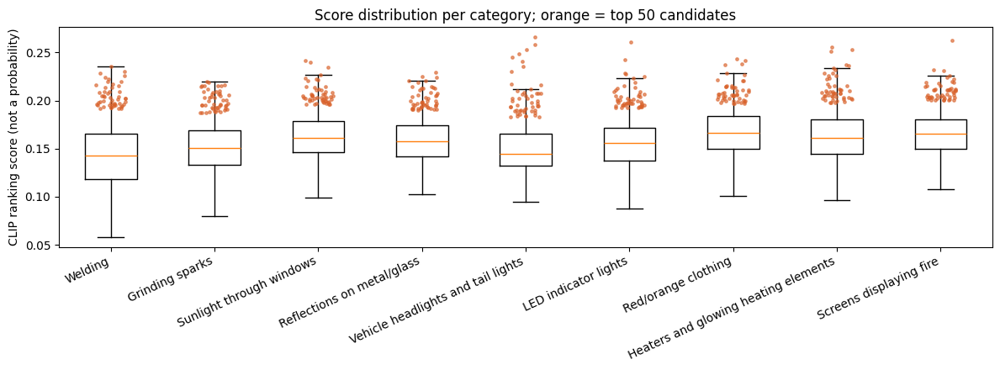

**Positive prompts: agreement with the ensembled category ranking**

,prompt_id,category,prompt,best_prompt_count_in_category_topk,overlap_with_category_topk
18,grinding_sparks__pos08,grinding_sparks,sparks bouncing off the floor while a man grin...,17,29
14,grinding_sparks__pos04,grinding_sparks,a worker cutting a steel pipe with a cut-off s...,14,32
12,grinding_sparks__pos02,grinding_sparks,bright metal sparks flying off a spinning grin...,8,33
15,grinding_sparks__pos05,grinding_sparks,long streaks of hot sparks spraying across a d...,3,22
17,grinding_sparks__pos07,grinding_sparks,close-up of a cutting disc on metal with a spr...,3,20
...,...,...,...,...,...
2,welding__pos03,welding,close-up of a welding torch producing a blindi...,1,35
4,welding__pos05,welding,arc welding in a dark workshop with a tiny ext...,1,35
6,welding__pos07,welding,TIG welding with a glowing tungsten electrode ...,1,31
10,welding__pos11,welding,welding fumes lit up by a bright arc flash in ...,1,28


In [30]:
fig, ax = plt.subplots(figsize=(12, 4.5))
data = [RANKINGS.loc[RANKINGS.category == c, "similarity_score"] for c in CATEGORIES]
ax.boxplot(data, showfliers=False)
for i, c in enumerate(CATEGORIES, 1):
    ax.scatter(np.full(len(TOPK[c]), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(TOPK[c])),
               TOPK[c]["similarity_score"], s=6, color="#d9622b", alpha=0.6, zorder=3)
ax.set_xticks(range(1, len(CATEGORIES) + 1), [CATEGORIES[c]["name"] for c in CATEGORIES], rotation=25, ha="right")
ax.set_ylabel("CLIP ranking score (not a probability)")
ax.set_title(f"Score distribution per category; orange = top {K} candidates")
fig.tight_layout()
fig.savefig(RUN_DIR / "score_distributions.png", dpi=130)
plt.show()

display(Markdown("**Positive prompts: agreement with the ensembled category ranking**"))
display(PROMPT_AGREEMENT.sort_values(["category", "best_prompt_count_in_category_topk"], ascending=[True, False]))

## 8. Contact sheets and full-resolution viewer

One sheet per category: **5 columns** with all top-K candidates in rank order. Each thumbnail is a fixed-size tile
with the aspect ratio preserved (letterboxed, never stretched or cropped). Captions show the rank, score, split, ID
and file name. Every image comes from the local FASDD copy. Missing or unreadable files show a labelled
placeholder.

contact sheets:   0%|          | 0/9 [00:00<?, ?it/s]

Saved: /content/clip_hard_negatives/runs/no_annotations_n500_seed42/contact_sheets


### Welding

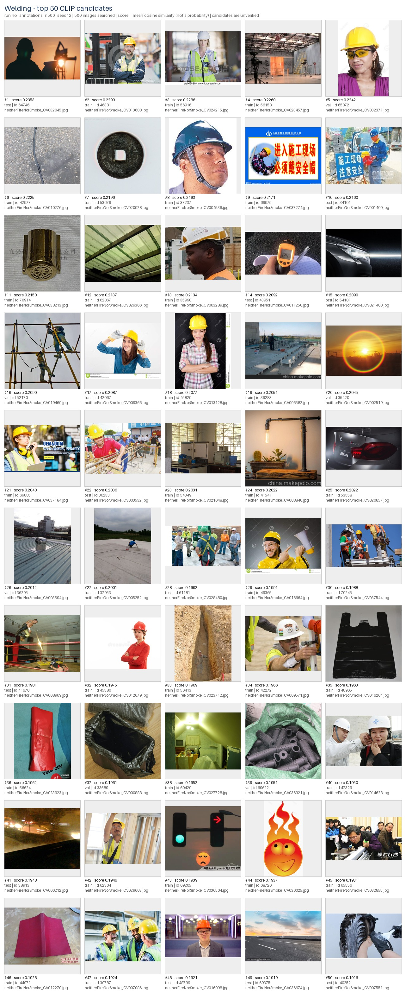

### Grinding sparks

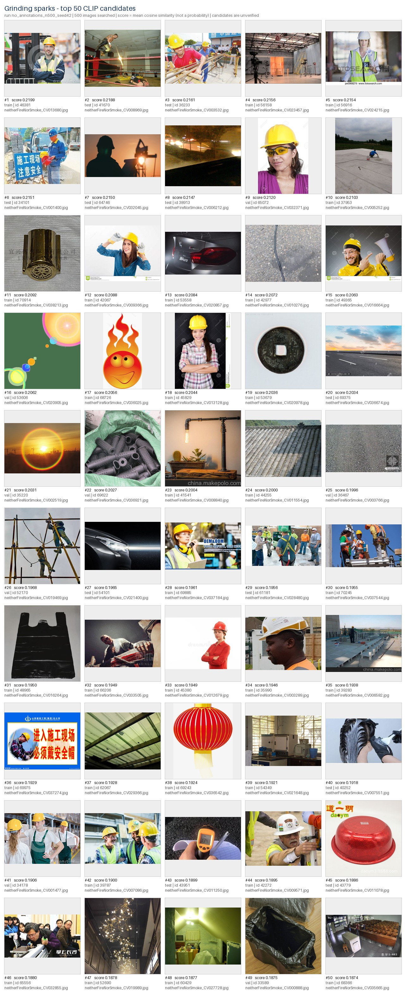

### Sunlight through windows

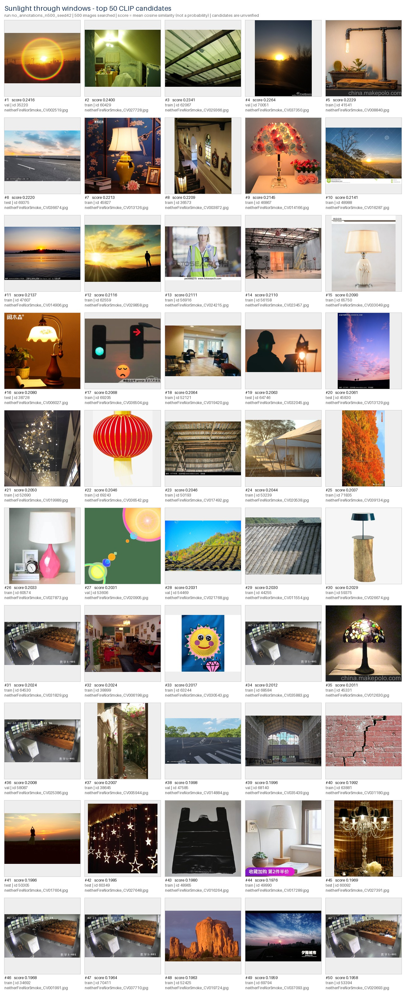

### Reflections on metal/glass

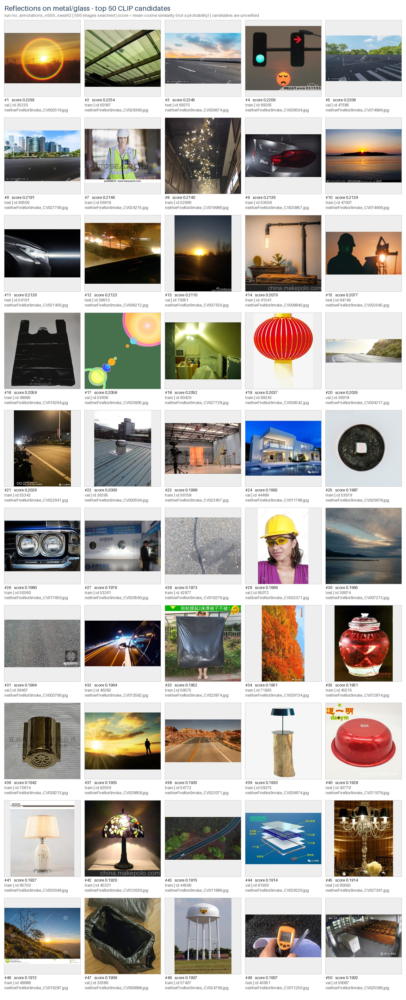

### Vehicle headlights and tail lights

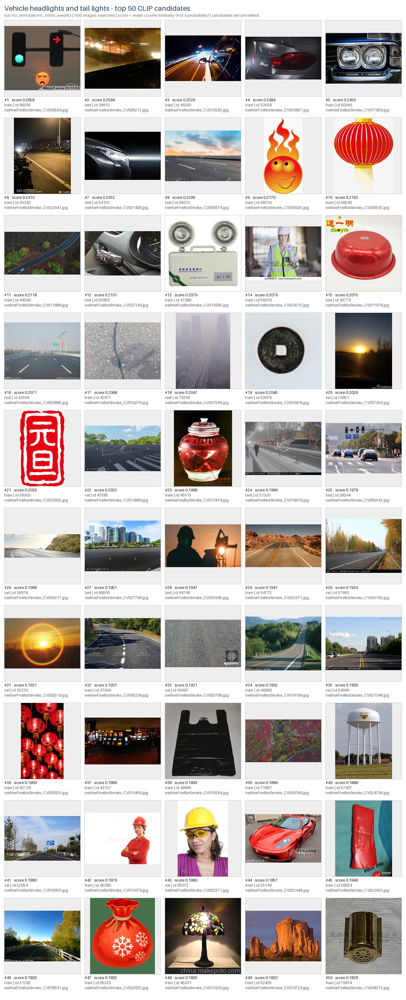

### LED indicator lights

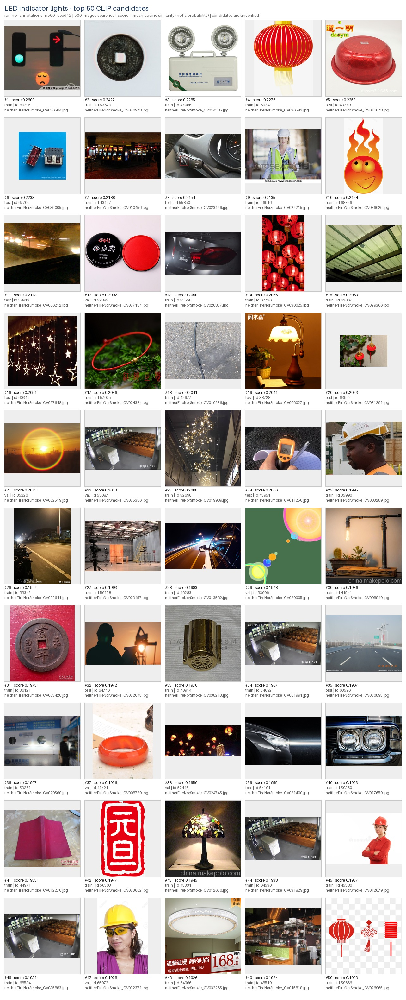

### Red/orange clothing

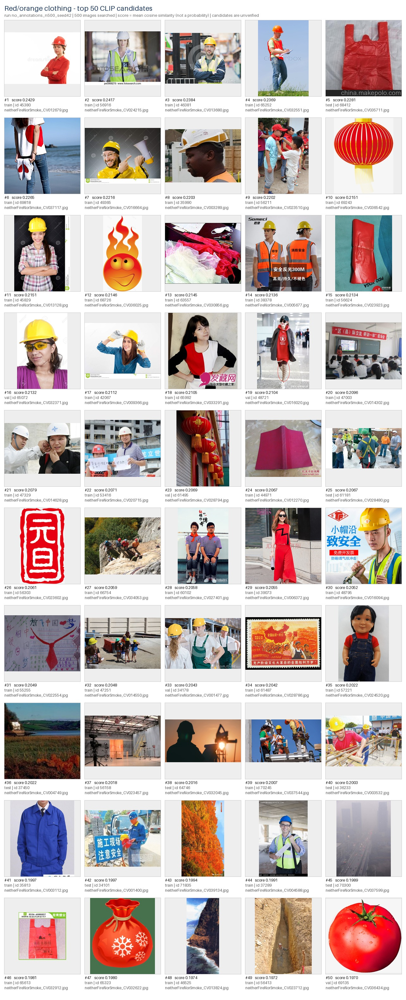

### Heaters and glowing heating elements

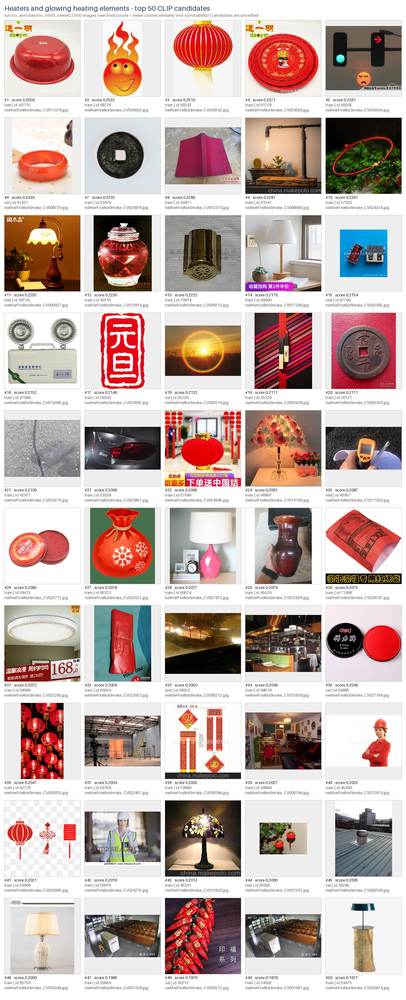

### Screens displaying fire

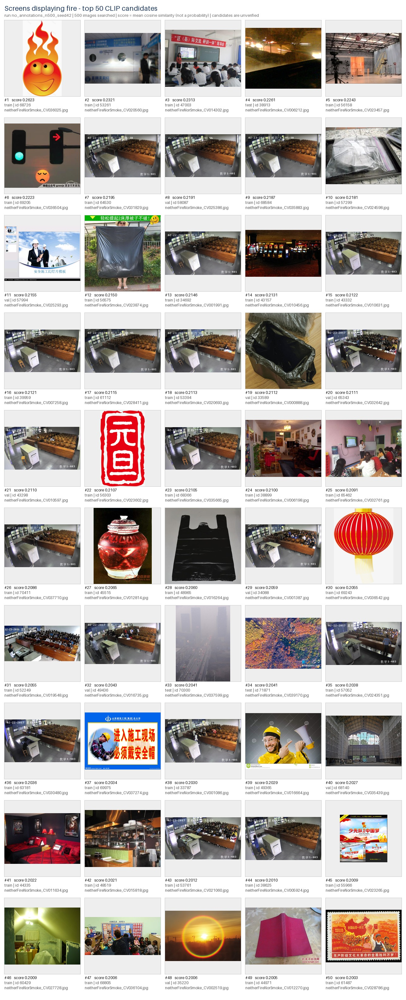

In [31]:
THUMB, PAD, COLS = 240, 14, 5


def get_font(size):
    for path in ("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", "DejaVuSans.ttf", "arial.ttf"):
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            pass
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()


FONT_TITLE, FONT_SUB, FONT_CAP = get_font(22), get_font(13), get_font(12)
LINE_H = 16
CAPTION_H = 3 * LINE_H + 6


def fit_text(draw, text, font, max_width):
    # Shorten long file names in the middle so the start and the numeric suffix stay visible.
    if draw.textlength(text, font=font) <= max_width:
        return text
    keep = len(text)
    while keep > 4:
        keep -= 1
        candidate = text[: keep // 2] + "..." + text[len(text) - (keep - keep // 2):]
        if draw.textlength(candidate, font=font) <= max_width:
            return candidate
    return text[:4] + "..."


def load_tile(path, size=THUMB):
    tile = Image.new("RGB", (size, size), (238, 238, 238))
    try:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((size, size), Image.Resampling.LANCZOS)  # keeps aspect ratio, never upsamples
        tile.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    except Exception:
        d = ImageDraw.Draw(tile)
        d.text((size // 2, size // 2), "missing / unreadable", fill=(160, 40, 40), font=FONT_CAP, anchor="mm")
    return tile


def make_contact_sheet(cat):
    df = TOPK[cat].reset_index(drop=True)  # positional index drives grid placement
    rows = max(1, math.ceil(len(df) / COLS))
    header = 64
    width = PAD + COLS * (THUMB + PAD)
    height = header + rows * (THUMB + CAPTION_H + PAD) + PAD
    sheet = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(sheet)
    draw.text((PAD, 12), f"{CATEGORIES[cat]['name']} - top {len(df)} CLIP candidates", fill=(31, 58, 95), font=FONT_TITLE)
    method = CONFIG["aggregation"] + (" minus contrastive" if CONFIG["subtract_contrastive"] else "")
    draw.text((PAD, 40), f"run {RUN_NAME} | {len(VALID):,} images searched | score = {method} cosine similarity "
                         f"(not a probability) | candidates are unverified", fill=(110, 110, 110), font=FONT_SUB)
    for pos, row in df.iterrows():
        r, c = divmod(pos, COLS)
        x, y = PAD + c * (THUMB + PAD), header + r * (THUMB + CAPTION_H + PAD)
        sheet.paste(load_tile(row.image_path), (x, y))
        draw.rectangle([x - 1, y - 1, x + THUMB, y + THUMB], outline=(200, 200, 200))
        lines = [f"#{row['rank']}   score {row.similarity_score:.4f}", f"{row.split} | id {row.image_id}",
                 fit_text(draw, row.file_name, FONT_CAP, THUMB)]
        for i, text in enumerate(lines):
            draw.text((x, y + THUMB + 4 + i * LINE_H), text, fill=(20, 20, 20) if i == 0 else (90, 90, 90), font=FONT_CAP)
    path = SHEET_DIR / f"{cat}.jpg"
    sheet.save(path, quality=92)
    return path


SHEETS = {cat: make_contact_sheet(cat) for cat in tqdm(CATEGORIES, desc="contact sheets")}
print("Saved:", SHEET_DIR)
if CONFIG["show_contact_sheets"]:
    from IPython.display import Image as IPImage
    for cat, path in SHEETS.items():
        display(Markdown(f"### {CATEGORIES[cat]['name']}"))
        display(IPImage(filename=str(path), width=1100))

In [32]:
def open_full(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert("RGB")


def show_full_resolution(category=None, rank=None, file_name=None):
    # Show one candidate at its native resolution, by (category, rank) or by file name.
    if file_name is not None:
        rows = INDEX[INDEX["file_name"] == file_name]
    else:
        rows = TOPK[category][TOPK[category]["rank"] == rank]
    if rows.empty:
        print("Not found.")
        return
    row = rows.iloc[0]
    print({k: row[k] for k in rows.columns if k in ("rank", "category", "split", "image_id", "file_name",
                                                       "similarity_score", "best_prompt", "image_path")})
    try:
        im = open_full(row.image_path)
        print(f"{im.width} x {im.height} px")
        display(im)
    except Exception as e:
        print("Cannot open image:", e)


# Example: show_full_resolution("welding", 1)   or   show_full_resolution(file_name="neitherFireNorSmoke_CV000575.jpg")
try:
    import ipywidgets as W
    if IN_COLAB:
        from google.colab import output as colab_output
        colab_output.enable_custom_widget_manager()
    v_cat = W.Dropdown(options=[(s["name"], c) for c, s in CATEGORIES.items()], description="Category")
    v_rank = W.BoundedIntText(value=1, min=1, max=K, description="Rank")
    v_btn, v_out = W.Button(description="Show full resolution", button_style="info"), W.Output()

    def _show(_):
        v_out.clear_output()
        with v_out:
            show_full_resolution(v_cat.value, v_rank.value)

    v_btn.on_click(_show)
    display(W.HBox([v_cat, v_rank, v_btn]), v_out)
except ImportError:
    print("ipywidgets not available - call show_full_resolution(category, rank) directly.")

Output()

## 9. Human verification

Review every candidate and choose one verdict:

| Verdict | Meaning |
|---|---|
| **Confirmed** | The category's visual condition is clearly present. |
| **Possible** | The condition may be present, but the image is ambiguous. |
| **Incorrect** | Unrelated to the category. |

Also tick **"Visible real flame"** if the image shows an actual flame despite having no fire annotation. That is a
labelling issue, not a hard negative. Verdicts are written to `verification/human_verification.csv` on every
navigation or save. The interface resumes where you stopped, and verdicts from earlier runs are imported when
`import_previous_reviews=True`. Without widgets, edit the CSV in a spreadsheet using the same status values.

In [33]:
VERIFY_PATH = VERIFY_DIR / "human_verification.csv"
STATUSES = ["Unreviewed", "Confirmed", "Possible", "Incorrect"]
REVIEW_COLS = ["verification_status", "visible_real_flame", "reviewer", "reviewer_comments", "reviewed_at_utc", "review_source"]
KEY = ["category", "uid"]


def read_reviews(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df["visible_real_flame"] = df["visible_real_flame"].str.lower().eq("true")
    return df


def build_verification_table():
    current = pd.concat([t[["category", "category_name", "rank", "uid", "split", "image_id", "file_name", "image_path",
                            "similarity_score", "best_prompt"]] for t in TOPK.values()], ignore_index=True)
    current["in_current_topk"] = True
    current = current.assign(verification_status="Unreviewed", visible_real_flame=False, reviewer="",
                             reviewer_comments="", reviewed_at_utc="", review_source="")
    sources = [VERIFY_PATH] if VERIFY_PATH.exists() else []
    if CONFIG["import_previous_reviews"]:
        sources += [p for p in sorted((OUTPUT_ROOT / "runs").glob("*/verification/human_verification.csv"))
                    if p != VERIFY_PATH]
    current = current.set_index(KEY)
    stale = []
    for src in sources:  # this run's own file first, so its verdicts take precedence
        old = read_reviews(src)
        old = old[old["verification_status"] != "Unreviewed"].set_index(KEY)
        hit = old.index.intersection(current.index)
        todo = hit[current.loc[hit, "verification_status"].eq("Unreviewed").to_numpy()]
        current.loc[todo, REVIEW_COLS] = old.loc[todo, REVIEW_COLS].to_numpy()
        if src != VERIFY_PATH:
            current.loc[todo, "review_source"] = src.parent.parent.name
        elif len(old.index.difference(current.index)):
            # Reviewed rows that left the top-K (e.g. aggregation changed) are kept, never discarded.
            s = old.loc[old.index.difference(current.index)].copy()
            s["in_current_topk"] = False
            stale.append(s)
    out = pd.concat([current] + stale).reset_index()
    out["in_current_topk"] = out["in_current_topk"].astype(str).str.lower().eq("true")
    return out


VERIFY = build_verification_table()


def save_verification():
    atomic_csv(VERIFY, VERIFY_PATH, float_format="%.5f")


save_verification()
print(f"{VERIFY_PATH}\n{(VERIFY.verification_status != 'Unreviewed').sum()} of {len(VERIFY)} rows already reviewed")

/content/clip_hard_negatives/runs/no_annotations_n500_seed42/verification/human_verification.csv
0 of 450 rows already reviewed


In [34]:
def preview_bytes(path, max_side=720):
    try:
        im = open_full(path)
        im.thumbnail((max_side, max_side), Image.Resampling.LANCZOS)
    except Exception:
        im = Image.new("RGB", (max_side, max_side // 2), (238, 238, 238))
        ImageDraw.Draw(im).text((20, 20), "missing / unreadable image", fill=(160, 40, 40), font=FONT_TITLE)
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=90)
    return buf.getvalue()


try:
    import ipywidgets as W
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets is not installed. Review by editing", VERIFY_PATH,
          "- set verification_status to Confirmed / Possible / Incorrect.")

if HAVE_WIDGETS:
    state = {"row": None}
    w_cat = W.Dropdown(options=[(s["name"], c) for c, s in CATEGORIES.items()], description="Category")
    w_img = W.Image(format="jpeg")
    w_info, w_progress = W.HTML(), W.HTML()
    w_status = W.ToggleButtons(options=STATUSES, description="Verdict",
                               tooltips=["Not reviewed yet", "Condition clearly present",
                                         "May be present, ambiguous", "Unrelated image"])
    w_flame = W.Checkbox(description="Visible real flame (possible missing fire annotation)", indent=False)
    w_comment = W.Textarea(placeholder="Reviewer comments", layout=W.Layout(width="100%", height="60px"))
    w_reviewer = W.Text(value=CONFIG["reviewer"], description="Reviewer")
    b_prev, b_next = W.Button(description="< Previous"), W.Button(description="Next >")
    b_unrev = W.Button(description="Next unreviewed", button_style="warning")
    b_save = W.Button(description="Save & next", button_style="success")
    b_full = W.Button(description="Full resolution")
    w_out = W.Output()

    def rows_for(cat):
        sel = VERIFY[(VERIFY["category"] == cat) & VERIFY["in_current_topk"]]
        return sel.assign(_r=sel["rank"].astype(int)).sort_values("_r").index.tolist()

    def commit():
        i = state["row"]
        if i is None:
            return
        new = dict(verification_status=w_status.value, visible_real_flame=bool(w_flame.value),
                   reviewer_comments=w_comment.value.strip(), reviewer=w_reviewer.value.strip())
        if any(VERIFY.at[i, k] != v for k, v in new.items() if k != "reviewer"):
            for k, v in new.items():
                VERIFY.at[i, k] = v
            VERIFY.at[i, "reviewed_at_utc"] = utc_now()
            VERIFY.at[i, "review_source"] = RUN_NAME
            save_verification()

    def load(i):
        state["row"] = i
        r = VERIFY.loc[i]
        w_img.value = preview_bytes(r.image_path)
        src = f" | imported from <i>{r.review_source}</i>" if r.review_source not in ("", RUN_NAME) else ""
        w_info.value = (f"<b>#{r['rank']}</b> &nbsp; score <b>{float(r.similarity_score):.4f}</b> &nbsp; "
                        f"{r.split} | id {r.image_id} | <code>{r.file_name}</code><br>"
                        f"best prompt: <i>{PROMPTS.set_index('prompt_id').at[r.best_prompt, 'text']}</i>{src}")
        w_status.value = r.verification_status if r.verification_status in STATUSES else "Unreviewed"
        w_flame.value = bool(r.visible_real_flame)
        w_comment.value = r.reviewer_comments
        update_progress()

    def update_progress():
        cur = VERIFY[VERIFY["in_current_topk"]]
        in_cat = cur[cur["category"] == w_cat.value]
        pos = rows_for(w_cat.value).index(state["row"]) + 1 if state["row"] in rows_for(w_cat.value) else 0
        w_progress.value = (f"Item {pos}/{len(in_cat)} | reviewed in category "
                            f"{(in_cat.verification_status != 'Unreviewed').sum()}/{len(in_cat)} | overall "
                            f"{(cur.verification_status != 'Unreviewed').sum()}/{len(cur)}")

    def step(delta):
        commit()
        rows = rows_for(w_cat.value)
        pos = rows.index(state["row"]) if state["row"] in rows else 0
        load(rows[max(0, min(len(rows) - 1, pos + delta))])

    def next_unreviewed(_=None):
        commit()
        rows = rows_for(w_cat.value)
        pos = rows.index(state["row"]) if state["row"] in rows else -1
        ordered = rows[pos + 1:] + rows[: pos + 1]
        todo = [i for i in ordered if VERIFY.at[i, "verification_status"] == "Unreviewed"]
        if todo:
            load(todo[0])
        else:
            w_out.clear_output()
            with w_out:
                print(f"All candidates in {CATEGORIES[w_cat.value]['name']} are reviewed.")

    def change_category(change):
        commit()
        state["row"] = None
        load(rows_for(change["new"])[0])

    def full(_):
        w_out.clear_output()
        with w_out:
            show_full_resolution(file_name=VERIFY.at[state["row"], "file_name"])

    b_prev.on_click(lambda _: step(-1))
    b_next.on_click(lambda _: step(1))
    b_save.on_click(lambda _: step(1))
    b_unrev.on_click(next_unreviewed)
    b_full.on_click(full)
    w_cat.observe(change_category, names="value")
    load(rows_for(w_cat.value)[0])
    display(W.VBox([W.HBox([w_cat, w_reviewer]), w_progress, w_img, w_info, w_status, w_flame, w_comment,
                    W.HBox([b_prev, b_next, b_save, b_unrev, b_full]), w_out]))

## 10. Verification summary and outputs

Run this after reviewing (re-run any time). Counts are in **this sample's** top-K only. A confirmed count shows that
the condition exists in FASDD at least that many times. It is not a prevalence estimate, and a low count in a
500-image pilot does not show that the condition is absent from the full dataset.

In [35]:
V = read_reviews(VERIFY_PATH)
V["in_current_topk"] = V["in_current_topk"].str.lower().eq("true")
cur = V[V["in_current_topk"]]
summary = (cur.groupby("category")["verification_status"].value_counts().unstack(fill_value=0)
           .reindex(index=list(CATEGORIES), columns=STATUSES, fill_value=0))
summary.insert(0, "category_name", [CATEGORIES[c]["name"] for c in summary.index])
summary["reviewed"] = summary[["Confirmed", "Possible", "Incorrect"]].sum(axis=1)
summary["confirmed_share_of_reviewed"] = (summary["Confirmed"] / summary["reviewed"].replace(0, np.nan)).round(3)
summary["visible_real_flame_flags"] = cur.groupby("category")["visible_real_flame"].sum().reindex(summary.index).fillna(0).astype(int)
summary["status"] = np.where(summary["Confirmed"] > 0, "present in sample (verified)",
                             np.where(summary["reviewed"] < summary[STATUSES].sum(axis=1), "review incomplete",
                                      "not established in this sample"))
summary = summary.reset_index()
atomic_csv(summary, RUN_DIR / "verification_summary.csv")
display(summary)

hard = V[V["verification_status"].isin(["Confirmed", "Possible"]) & ~V["visible_real_flame"]]
HARD_NEGATIVES = (hard.groupby(["uid", "split", "image_id", "file_name", "image_path"])
                  .apply(lambda g: pd.Series(dict(
                      categories=";".join(g["category"]),
                      verdicts=";".join(f"{c}:{s}" for c, s in zip(g["category"], g["verification_status"])),
                      any_confirmed="Confirmed" in set(g["verification_status"]))), include_groups=False)
                  .reset_index()) if len(hard) else pd.DataFrame(
    columns=["uid", "split", "image_id", "file_name", "image_path", "categories", "verdicts", "any_confirmed"])
atomic_csv(HARD_NEGATIVES, VERIFY_DIR / "hard_negative_candidates.csv")
FLAME_FLAGS = V[V["visible_real_flame"]].drop_duplicates("uid")
atomic_csv(FLAME_FLAGS, VERIFY_DIR / "possible_missing_flame_annotations.csv")
print(f"Hard-negative images (Confirmed/Possible): {len(HARD_NEGATIVES)} | "
      f"possible missing flame annotations: {len(FLAME_FLAGS)}")

verification_status,category,category_name,Unreviewed,Confirmed,Possible,Incorrect,reviewed,confirmed_share_of_reviewed,visible_real_flame_flags,status
0,welding,Welding,50,0,0,0,0,NaN,0,review incomplete
1,grinding_sparks,Grinding sparks,50,0,0,0,0,NaN,0,review incomplete
2,sunlight_windows,Sunlight through windows,50,0,0,0,0,NaN,0,review incomplete
3,reflections_metal_glass,Reflections on metal/glass,50,0,0,0,0,NaN,0,review incomplete
4,vehicle_lights,Vehicle headlights and tail lights,50,0,0,0,0,NaN,0,review incomplete
5,led_indicators,LED indicator lights,50,0,0,0,0,NaN,0,review incomplete
6,red_orange_clothing,Red/orange clothing,50,0,0,0,0,NaN,0,review incomplete
7,heaters,Heaters and glowing heating elements,50,0,0,0,0,NaN,0,review incomplete
8,screens_fire,Screens displaying fire,50,0,0,0,0,NaN,0,review incomplete


Hard-negative images (Confirmed/Possible): 0 | possible missing flame annotations: 0


In [36]:
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


RUN_RECORD = dict(run_name=RUN_NAME, created_utc=utc_now(), config=CONFIG, environment=ENVIRONMENT,
                  sample_size=len(SAMPLE), embedded=len(VALID), unreadable=len(UNREADABLE),
                  missing_candidate_files=len(MISSING), sample_sha256=SAMPLE_HASH, allocation=allocation,
                  prompts=int(len(PROMPTS)), embedding_dim=EMB_DIM)
atomic_json(RUN_RECORD, RUN_DIR / "run_config.json")

report = f'''# CLIP hard-negative discovery - {RUN_NAME}

Generated {utc_now()} | {CONFIG["model_name"]} on {GPU_NAME or DEVICE} | seed {CONFIG["seed"]}

## Data
Candidate pool: **{CONFIG["candidate_pool"]}** ({len(POOL):,} images with readable paths; {len(MISSING)} missing files).
Sample: {len(SAMPLE):,} images, allocated proportionally per split {allocation}; sample sha256 `{SAMPLE_HASH[:16]}`.
Embedded {len(VALID):,}; unreadable {len(UNREADABLE)}. Dataset warnings: {warnings or "none"}.

## Method
Frozen CLIP; {len(PROMPTS)} prompts (positive, contrastive and fire-probe). Category score =
{CONFIG["aggregation"]} cosine similarity over positive prompts{" minus best contrastive score" if CONFIG["subtract_contrastive"] else ""};
top {K} per category reviewed by a person. Scores are retrieval similarities, not probabilities.

## Verification results (current top-{K})
{md_table(summary[["category_name", "Confirmed", "Possible", "Incorrect", "Unreviewed", "visible_real_flame_flags", "status"]])}

Hard-negative images (Confirmed/Possible, no visible real flame): {len(HARD_NEGATIVES)}.
Images flagged as showing a real but unannotated flame: {len(FLAME_FLAGS)}.

## Interpretation limits
- Confirmed counts are lower bounds within this sample, not prevalence estimates.
- "Not established in this sample" does not mean absent; scale `sample_size` up before concluding.
- Images without annotations are not verified negatives; flagged flames need label review.
- Still images cannot show flicker or flashing behaviour.
'''
(RUN_DIR / "summary_report.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# CLIP hard-negative discovery - no_annotations_n500_seed42

Generated 2026-10-31T16:39:39Z | ViT-B/32 on Tesla T4 | seed 42

## Data
Candidate pool: **no_annotations** (39,199 images with readable paths; 0 missing files).
Sample: 500 images, allocated proportionally per split {'train': 334, 'val': 83, 'test': 83}; sample sha256 `429876c43d724ea6`.
Embedded 500; unreadable 0. Dataset warnings: none.

## Method
Frozen CLIP; 134 prompts (positive, contrastive and fire-probe). Category score =
mean cosine similarity over positive prompts;
top 50 per category reviewed by a person. Scores are retrieval similarities, not probabilities.

## Verification results (current top-50)
| category_name | Confirmed | Possible | Incorrect | Unreviewed | visible_real_flame_flags | status |
|---|---|---|---|---|---|---|
| Welding | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Grinding sparks | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Sunlight through windows | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Reflections on metal/glass | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Vehicle headlights and tail lights | 0 | 0 | 0 | 50 | 0 | review incomplete |
| LED indicator lights | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Red/orange clothing | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Heaters and glowing heating elements | 0 | 0 | 0 | 50 | 0 | review incomplete |
| Screens displaying fire | 0 | 0 | 0 | 50 | 0 | review incomplete |

Hard-negative images (Confirmed/Possible, no visible real flame): 0.
Images flagged as showing a real but unannotated flame: 0.

## Interpretation limits
- Confirmed counts are lower bounds within this sample, not prevalence estimates.
- "Not established in this sample" does not mean absent; scale `sample_size` up before concluding.
- Images without annotations are not verified negatives; flagged flames need label review.
- Still images cannot show flicker or flashing behaviour.


In [37]:
# Optional: bundle this run's outputs (everything except the shared embedding cache) into one ZIP.
DOWNLOAD_ZIP = False
if DOWNLOAD_ZIP:
    archive = shutil.make_archive(str(Path("/content") / f"clip_hard_negatives_{RUN_NAME}"), "zip", RUN_DIR)
    print("Created", archive)
    if IN_COLAB:
        from google.colab import files
        files.download(archive)
print("All outputs are in", RUN_DIR)

All outputs are in /content/clip_hard_negatives/runs/no_annotations_n500_seed42
